# Demo -- classificador em cromossomos individuais

Carrega o modelo final e roda a predição em cromossomos individuais, para inspecionar visualmente acertos e erros em casos concretos (as métricas agregadas estão em `03_eval.ipynb`).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

import cv2
import numpy as np
import torch
import torch.nn.functional as functional
import matplotlib.pyplot as plt

from dataset import load_manifest, preprocess
from evaluate import load_checkpoint_with_meta
from train import CROPS_ROOT, MANIFEST
from voc_to_yolo import DENVER_CLASSES

CHECKPOINT = Path("../runs/resnet50-paper/best.pt")  # modelo final

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, meta = load_checkpoint_with_meta(CHECKPOINT, device)
print(f"Checkpoint carregado em {device}: {CHECKPOINT} (resize: {meta['resize']})")

Checkpoint carregado em cuda: ../runs/resnet50-paper/best.pt (resize: stretch)


Função auxiliar: recebe um recorte (grayscale, como salvo por `extract_crops.py`) e devolve as probabilidades por classe -- mesmo pré-processamento usado na avaliação (resize lido do checkpoint + normalização ImageNet), sem augmentation.

In [2]:
@torch.no_grad()
def predict_crop(image_gray: np.ndarray) -> np.ndarray:
    tensor = preprocess(image_gray, meta["image_size"], meta["resize"]).unsqueeze(0).to(device)
    logits = model(tensor)
    return functional.softmax(logits, dim=1).cpu().numpy()[0]

## 1. Amostra aleatória do split de teste

Recortes que o modelo nunca viu em treino/validação, com a predição ao lado do rótulo verdadeiro -- título em verde quando acerta, vermelho quando erra.

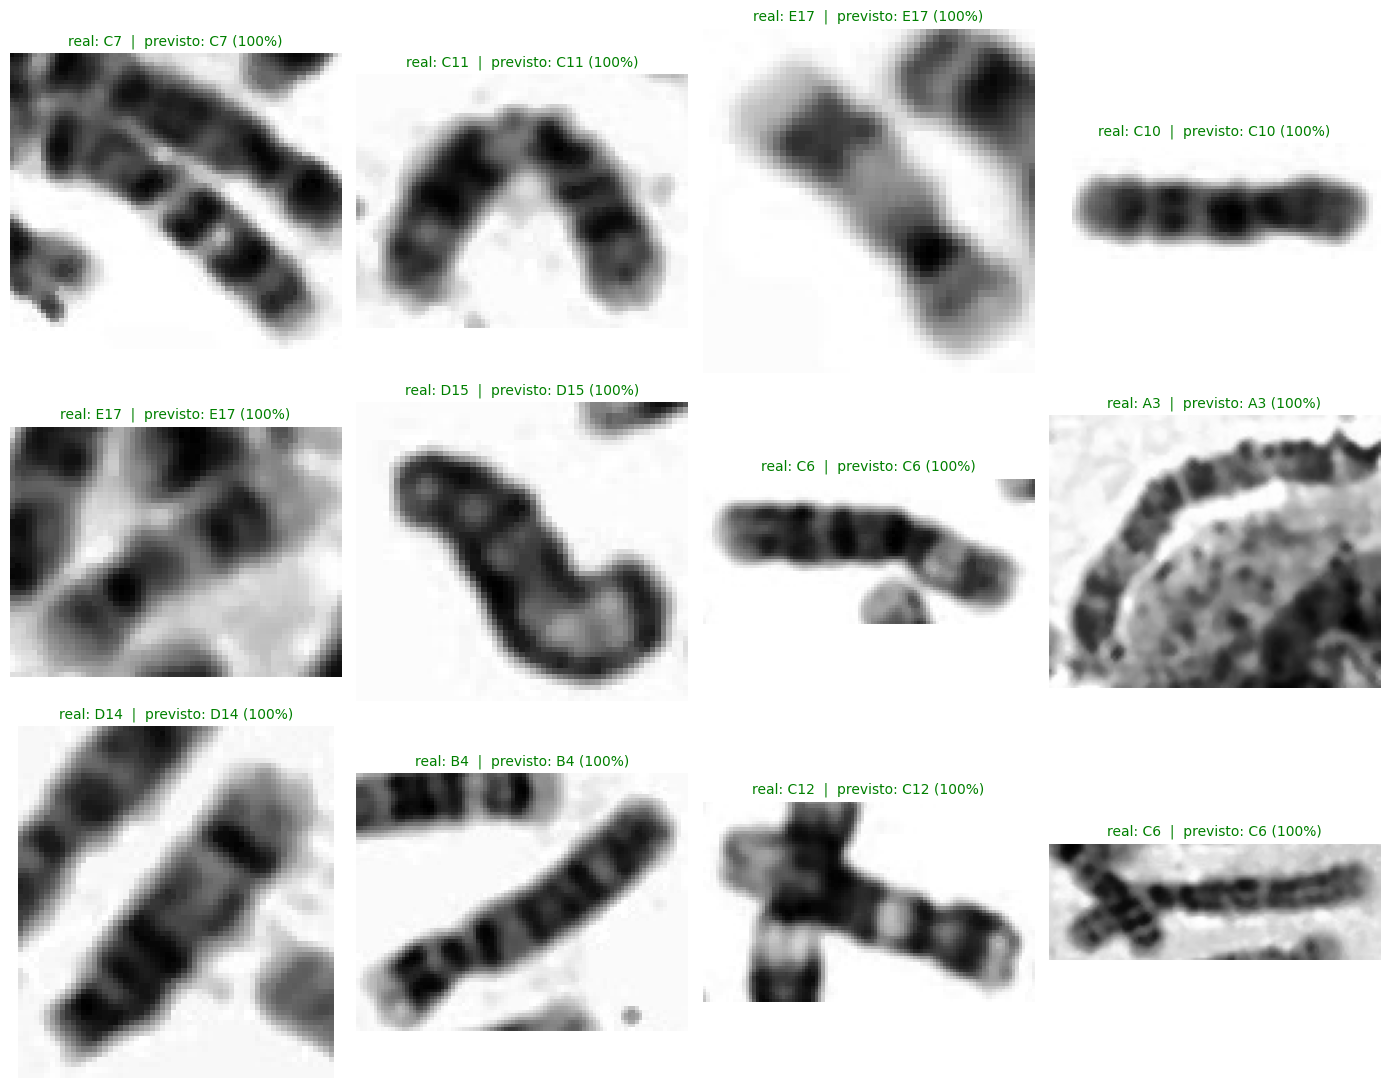

In [3]:
import random

rows = load_manifest(MANIFEST, "test")
sample = random.sample(rows, 12)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, row in zip(axes.flat, sample, strict=True):
    image = cv2.imread(str(CROPS_ROOT / row["path"]), cv2.IMREAD_GRAYSCALE)
    probs = predict_crop(image)
    pred_id = int(probs.argmax())
    true_id = int(row["class_id"])
    pred_name, true_name = DENVER_CLASSES[pred_id], DENVER_CLASSES[true_id]
    color = "green" if pred_id == true_id else "red"

    ax.imshow(image, cmap="gray")
    ax.set_title(f"real: {true_name}  |  previsto: {pred_name} ({probs[pred_id]:.0%})", color=color, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Predição para um recorte específico

`CROP_PATH` aponta para um recorte já extraído (`data/processed/classification/{train,val,test}/<classe>/*.png`) -- ou para outra imagem de cromossomo isolado, em escala de cinza e fundo claro. A saída são as 5 classes mais prováveis segundo o modelo.

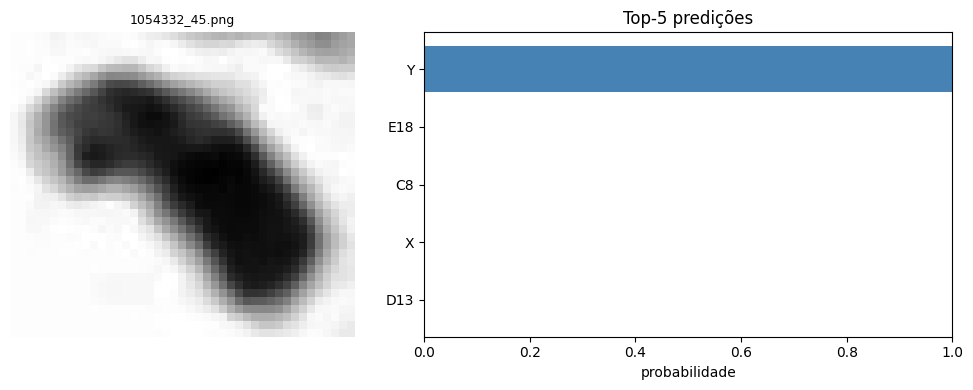

Classe verdadeira (pelo caminho do arquivo): Y


In [4]:
CROP_PATH = CROPS_ROOT / "test" / "Y" / next((CROPS_ROOT / "test" / "Y").glob("*.png")).name

image = cv2.imread(str(CROP_PATH), cv2.IMREAD_GRAYSCALE)
probs = predict_crop(image)
top5 = probs.argsort()[::-1][:5]

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ax_img.imshow(image, cmap="gray")
ax_img.set_title(CROP_PATH.name, fontsize=9)
ax_img.axis("off")

names = [DENVER_CLASSES[i] for i in top5]
ax_bar.barh(names[::-1], probs[top5][::-1], color="steelblue")
ax_bar.set_xlim(0, 1)
ax_bar.set_xlabel("probabilidade")
ax_bar.set_title("Top-5 predições")
plt.tight_layout()
plt.show()

print(f"Classe verdadeira (pelo caminho do arquivo): {CROP_PATH.parent.name}")